# مرحله سوم: Data Preparation
## آماده‌سازی داده‌ها

در این مرحله داده‌های خام Online Retail را برای تحلیل و مدل‌سازی آماده می‌کنیم.

در مرحله قبل ساختار داده‌ها، مقادیر گمشده، رکوردهای تکراری و الگوهای خرید را بررسی کردیم. اکنون می‌خواهیم داده‌های موردنیاز را انتخاب کنیم، مشکلات آن‌ها را برطرف کنیم و ویژگی‌های جدیدی برای تحلیل رفتار مشتریان بسازیم.

هدف اصلی این مرحله آماده‌سازی یک دیتاست در سطح مشتری است؛ یعنی به‌جای اینکه هر سطر نشان‌دهنده یک ردیف از فاکتور باشد، هر سطر اطلاعات یک مشتری را نمایش دهد.


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("Online Retail.xlsx")

pd.set_option("display.max_columns", None)

print(df.head())
print(df.shape)

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
(541909, 8)


# بخش اول: Data Selection
## انتخاب داده‌ها

### **سؤال ۱: براساس تحلیل مرحله قبل، کدام ستون‌ها برای پروژه ما اهمیت بیشتری دارند؟**

**هدف از پرسیدن:**

هدف این سؤال انتخاب ستون‌هایی است که برای تحلیل رفتار خرید مشتریان و شناسایی مشتریان در معرض ریزش موردنیاز هستند.

در دیتاست ما ستون `target` وجود ندارد؛ بنابراین نمی‌توانیم مانند پروژه بیماری قلبی، ویژگی‌ها را براساس همبستگی با Target انتخاب کنیم.

**پاسخ:**

ستون‌های مهم برای پروژه ما عبارت‌اند از:

- `CustomerID`: شناسه مشتری
- `InvoiceNo`: شماره فاکتور
- `InvoiceDate`: تاریخ خرید
- `Quantity`: تعداد محصولات خریداری‌شده
- `UnitPrice`: قیمت هر واحد محصول
- `Country`: کشور مشتری


In [13]:
selected_columns = [
    "CustomerID",
    "InvoiceNo",
    "InvoiceDate",
    "Quantity",
    "UnitPrice",
    "Country"
]

selected_df = df[selected_columns].copy()

print(selected_df.head())
print("Shape:", selected_df.shape)

   CustomerID InvoiceNo         InvoiceDate  Quantity  UnitPrice  \
0     17850.0    536365 2010-12-01 08:26:00         6       2.55   
1     17850.0    536365 2010-12-01 08:26:00         6       3.39   
2     17850.0    536365 2010-12-01 08:26:00         8       2.75   
3     17850.0    536365 2010-12-01 08:26:00         6       3.39   
4     17850.0    536365 2010-12-01 08:26:00         6       3.39   

          Country  
0  United Kingdom  
1  United Kingdom  
2  United Kingdom  
3  United Kingdom  
4  United Kingdom  
Shape: (541909, 6)


**تحلیل:**

ستون‌های انتخاب‌شده اطلاعات اصلی موردنیاز برای بررسی رفتار خرید مشتریان را فراهم می‌کنند. شناسه مشتری برای تفکیک مشتریان، شماره فاکتور برای محاسبه تعداد خریدها، تاریخ خرید برای محاسبه تازگی خرید و تعداد و قیمت محصولات برای محاسبه ارزش خرید استفاده می‌شوند.

بنابراین این ستون‌ها برای ساخت ویژگی‌های RFM کافی هستند.


## **سؤال ۲: کدام ستون‌ها برای ساخت ویژگی‌های RFM ضروری هستند؟**

**هدف از پرسیدن:**

مشخص کردن اطلاعات موردنیاز برای محاسبه سه ویژگی اصلی رفتار مشتریان.

**پاسخ:**

برای محاسبه ویژگی‌های RFM به اطلاعات زیر نیاز داریم:

- Recency: از ستون InvoiceDate
- Frequency: از ستون InvoiceNo
- Monetary: از ستون‌های Quantity و UnitPrice
- CustomerID: برای شناسایی و گروه‌بندی مشتریان

In [ ]:
print("RFM Required Columns:")
print([
    "CustomerID",
    "InvoiceNo",
    "InvoiceDate",
    "Quantity",
    "UnitPrice"
])

**تحلیل:**

هر پنج ستون برای ساخت RFM کاربرد دارند. با استفاده از آن‌ها می‌توان میزان تازگی خرید، تعداد دفعات خرید و مجموع ارزش خرید هر مشتری را محاسبه کرد.

این سه ویژگی در مرحله بعد برای گروه‌بندی مشتریان بر اساس رفتار خرید استفاده می‌شوند.

---

# بخش دوم: پاک‌سازی داده‌ها (Data Cleaning)

## **سؤال ۳: آیا داده‌های گمشده در ستون‌های مهم وجود دارند؟**

**هدف از پرسیدن:**

شناسایی مقادیر خالی که ممکن است باعث ایجاد مشکل در محاسبات شوند.

**پاسخ:**

با استفاده از کد زیر تعداد و درصد مقادیر گمشده هر ستون را بررسی می‌کنیم.


In [14]:
print("Missing Values:")
print(selected_df.isnull().sum())

missing_percent = (
    selected_df.isnull().sum() / len(selected_df)
) * 100

print("Missing Percentage:")
print(missing_percent)

Missing Values:
CustomerID     135080
InvoiceNo           0
InvoiceDate         0
Quantity            0
UnitPrice           0
Country             0
dtype: int64
Missing Percentage:
CustomerID     24.926694
InvoiceNo       0.000000
InvoiceDate     0.000000
Quantity        0.000000
UnitPrice       0.000000
Country         0.000000
dtype: float64


**تحلیل:**

خروجی نشان می‌دهد هر ستون چه تعداد مقدار گمشده دارد. وجود مقدار گمشده در CustomerID اهمیت زیادی دارد؛ زیرا بدون شناسه مشتری نمی‌توان تراکنش را به یک مشتری مشخص نسبت داد.

همچنین نبود تاریخ خرید یا اطلاعات قیمت و تعداد می‌تواند محاسبه ویژگی‌های RFM را با مشکل مواجه کند.

## **سؤال ۴: آیا رکوردهای تکراری در دیتاست وجود دارند؟**

**هدف از پرسیدن:**

شناسایی رکوردهای تکراری برای جلوگیری از محاسبه چندباره اطلاعات یکسان.

In [15]:
duplicate_count = selected_df.duplicated().sum()

print("Number of Duplicate Rows:")
print(duplicate_count)
clean_df = selected_df.drop_duplicates().copy()

print("Shape After Removing Duplicates:")
print(clean_df.shape)

Number of Duplicate Rows:
237175
Shape After Removing Duplicates:
(304734, 6)


**تحلیل:**

اگر تعداد رکوردهای تکراری بیشتر از صفر باشد، نشان می‌دهد برخی اطلاعات چند بار در دیتاست ثبت شده‌اند.

حذف رکوردهای کاملاً تکراری باعث می‌شود محاسبات تعداد خرید و ارزش خرید مشتریان تحت تأثیر ثبت چندباره اطلاعات قرار نگیرد.


## **سؤال ۵: آیا تراکنش‌های لغوشده یا مرجوعی در دیتاست وجود دارند؟**

**هدف از پرسیدن:**

شناسایی فاکتورهای لغوشده و تراکنش‌های مرجوعی؛ زیرا نباید آن‌ها را به‌عنوان خرید مثبت در محاسبه RFM در نظر بگیریم.

**پاسخ:**

شماره فاکتورهایی که با حرف C شروع می‌شوند، نشان‌دهنده تراکنش‌های لغوشده هستند.


In [42]:
cancelled_transactions = clean_df[
    clean_df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Cancelled Transactions:")
print(len(cancelled_transactions))

returns = clean_df[
    (clean_df["Quantity"] < 0) |
    (clean_df["UnitPrice"] < 0)
]

print("Negative Transactions:")
print(len(returns))

Cancelled Transactions:
8272
Negative Transactions:
9610


**تحلیل:**

تعداد تراکنش‌های لغوشده و دارای مقادیر منفی مشخص می‌شود. این تراکنش‌ها می‌توانند باعث کاهش یا تغییر غیرواقعی ارزش خرید مشتری شوند.

به همین دلیل در محاسبه RFM فقط خریدهای معتبر را در نظر می‌گیریم. البته اطلاعات مرجوعی و لغو برای تحلیل‌های جداگانه قابل استفاده هستند.


## **سؤال ۶: آیا مقادیر نامعتبر مانند تعداد یا قیمت صفر و منفی وجود دارند؟**

**هدف از پرسیدن:**

شناسایی اطلاعات نامعتبر که می‌توانند محاسبات ارزش خرید مشتریان را تحت تأثیر قرار دهند.

**پاسخ:**

ابتدا تعداد این مقادیر را بررسی می‌کنیم.

In [45]:
print("Quantity <= 0:")
print((clean_df["Quantity"] <= 0).sum())

print("UnitPrice <= 0:")
print((clean_df["UnitPrice"] <= 0).sum())
      
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"],
    errors="coerce"
)

clean_df = clean_df.dropna(
    subset=[
        "CustomerID",
        "InvoiceNo",
        "InvoiceDate",
        "Quantity",
        "UnitPrice"
    ]
)

clean_df = clean_df[
    (~clean_df["InvoiceNo"].astype(str).str.startswith("C")) &
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
].copy()

print("Valid Purchase Data:")
print(clean_df.shape)

Quantity <= 0:
9608
UnitPrice <= 0:
2205
Valid Purchase Data:
(247427, 7)


**تحلیل:**

پس از اجرای کد، فقط تراکنش‌هایی باقی می‌مانند که دارای شناسه مشتری، تاریخ، تعداد و قیمت معتبر باشند.

حذف مقادیر صفر و منفی باعث می‌شود محاسبه ارزش خرید مشتریان بر اساس خریدهای مثبت انجام شود.


## **سؤال ۷: آیا داده‌های پرت در ستون‌های Quantity و UnitPrice وجود دارند؟**

**هدف از پرسیدن:**

شناسایی مقادیر بسیار بزرگ یا غیرعادی که ممکن است بر تحلیل رفتار مشتریان تأثیر بگذارند.

**پاسخ:**

برای شناسایی داده‌های پرت از روش IQR استفاده می‌کنیم.


Column: Quantity
Number of Outliers: 23551
Column: UnitPrice
Number of Outliers: 24775


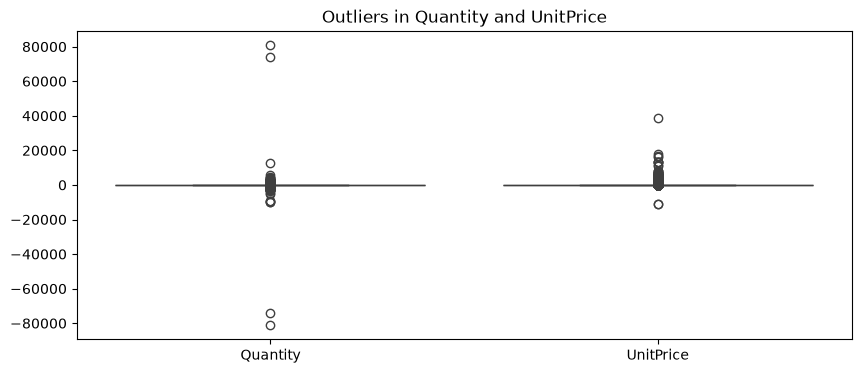

In [19]:
for column in ["Quantity", "UnitPrice"]:

    Q1 = clean_df[column].quantile(0.25)
    Q3 = clean_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = clean_df[
        (clean_df[column] < lower_limit) |
        (clean_df[column] > upper_limit)
    ]

    print("Column:", column)
    print("Number of Outliers:", len(outliers))

plt.figure(figsize=(10, 4))

sns.boxplot(data=clean_df[["Quantity", "UnitPrice"]])

plt.title("Outliers in Quantity and UnitPrice")
plt.show()

**تحلیل:**

در نمودار Boxplot نقاط خارج از محدوده اصلی داده‌ها به‌عنوان مقادیر پرت نمایش داده می‌شوند.

وجود داده پرت لزوماً به معنی اشتباه بودن آن نیست؛ ممکن است برخی مشتریان واقعاً خریدهای بزرگ‌تری داشته باشند. بنابراین در این مرحله داده‌های پرت را به‌صورت خودکار حذف نمی‌کنیم.

---


### **سؤال 8: با استفاده از Boxplot و IQR مقادیر پرت ویژگی‌های عددی را پیدا کنید.**

**هدف از پرسیدن:**

هدف شناسایی مقادیر بسیار بزرگ یا کوچک در ستون‌های عددی است. این مقادیر ممکن است ناشی از خطای ثبت اطلاعات یا خریدهای غیرمعمول باشند.


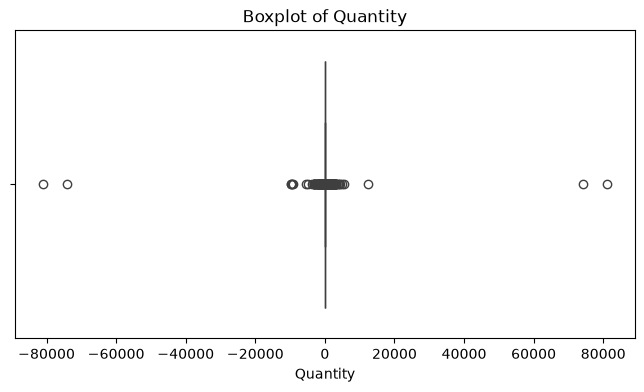

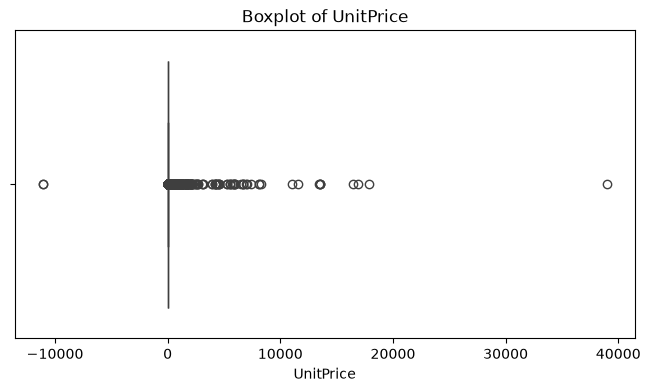

Quantity
تعداد Outlier: 23551

UnitPrice
تعداد Outlier: 24775



In [17]:
numeric_columns = ["Quantity", "UnitPrice"]

for column in numeric_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=clean_df[column])

    plt.title("Boxplot of " + column)

    plt.show()
    
for column in numeric_columns:

    Q1 = clean_df[column].quantile(0.25)

    Q3 = clean_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR

    upper_limit = Q3 + 1.5 * IQR

    outliers = clean_df[
        (clean_df[column] < lower_limit) |
        (clean_df[column] > upper_limit)
    ]

    print(column)
    print("تعداد Outlier:", len(outliers))
    print()

**تحلیل:**

با استفاده از Boxplot و روش IQR می‌توان مقادیر پرت را شناسایی کرد. در فروشگاه آنلاین، تعداد زیاد یک محصول ممکن است ناشی از خرید عمده باشد؛ بنابراین هر مقدار پرت الزاماً اشتباه نیست و نباید بدون بررسی حذف شود.

---

### **سؤال 9: جدولی از تعداد Outlier هر ویژگی ایجاد کنید.**

**هدف از پرسیدن:**

هدف مقایسه تعداد مقادیر پرت در ستون‌های عددی و مشخص کردن ویژگی‌هایی است که پراکندگی غیرعادی بیشتری دارند.


In [18]:
outlier_summary = []

for column in numeric_columns:

    Q1 = clean_df[column].quantile(0.25)

    Q3 = clean_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR

    upper_limit = Q3 + 1.5 * IQR

    count = (
        (clean_df[column] < lower_limit) |
        (clean_df[column] > upper_limit)
    ).sum()

    outlier_summary.append({
        "Feature": column,
        "Number of Outliers": count
    })

outlier_table = pd.DataFrame(outlier_summary)

print(outlier_table)

     Feature  Number of Outliers
0   Quantity               23551
1  UnitPrice               24775


**تحلیل:**

این جدول تعداد مقادیر پرت هر ویژگی را نشان می‌دهد. با بررسی آن می‌توان مشخص کرد کدام ویژگی‌ها نیازمند بررسی بیشتری هستند. تعداد زیاد Outlier به‌تنهایی دلیل حذف یک ویژگی یا رکورد نیست.

---


### **سؤال 10: برای مدیریت Outlierها سه استراتژی مختلف پیشنهاد دهید.**

**هدف از پرسیدن:**

هدف آشنایی با روش‌های مختلف برخورد با مقادیر پرت است.

**پاسخ:**

سه روش اصلی عبارت‌اند از:

1. **حذف Outlier:** در صورتی که مقدار واقعاً اشتباه یا نامعتبر باشد.
2. **جایگزینی یا محدود کردن مقادیر:** می‌توان مقادیر بسیار بزرگ یا کوچک را به یک محدوده مشخص محدود کرد.
3. **تبدیل داده:** با استفاده از تبدیل‌هایی مانند لگاریتم می‌توان اثر مقادیر بسیار بزرگ را کاهش داد.

**تحلیل:**

در پروژه ما خریدهای بزرگ ممکن است واقعی باشند. بنابراین حذف همه مقادیر پرت مناسب نیست. بهتر است ابتدا تراکنش‌های نامعتبر را شناسایی کنیم و برای کاهش اثر مقادیر بسیار بزرگ در ویژگی‌های مشتری از تبدیل مناسب استفاده کنیم.

---

# بخش سوم: Data Construction
## ساخت ویژگی‌های جدید

در این بخش اطلاعات تراکنش‌ها را به اطلاعاتی در سطح مشتری تبدیل می‌کنیم.

سه ویژگی اصلی پروژه عبارت‌اند از:

- Recency
- Frequency
- Monetary

### **سؤال 11: مشتریان را براساس فاصله زمانی از آخرین خرید به سه گروه تقسیم کنید.**

**هدف از پرسیدن:**

در پروژه اصلی مدرس، سن بیماران به سه گروه تقسیم شده است. در پروژه ما، این سؤال را به گروه‌بندی مشتریان براساس فاصله از آخرین خرید تبدیل می‌کنیم.

این ویژگی کمک می‌کند مشتریانی را که اخیراً خرید داشته‌اند از مشتریانی که مدت زیادی خرید نکرده‌اند جدا کنیم.


In [34]:
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"],
    errors="coerce"
)

# تاریخ مرجع
reference_date = clean_df["InvoiceDate"].max() + pd.Timedelta(days=1)

# محاسبه آخرین خرید هر مشتری
last_purchase = clean_df.groupby("CustomerID")["InvoiceDate"].max()

# محاسبه Recency
recency = (reference_date - last_purchase).dt.days

customer_df = pd.DataFrame({
    "CustomerID": recency.index,
    "Recency": recency.values
})

# تقسیم مشتریان به سه گروه
customer_df["Recency_Group"] = pd.cut(
    customer_df["Recency"],
    bins=[-1, 30, 90, float("inf")],
    labels=["Recent", "At Risk", "Inactive"]
)

print(customer_df.head(10))

   CustomerID  Recency Recency_Group
0     12346.0      326      Inactive
1     12347.0        2        Recent
2     12348.0       75       At Risk
3     12349.0       19        Recent
4     12350.0      310      Inactive
5     12352.0       36       At Risk
6     12353.0      204      Inactive
7     12354.0      232      Inactive
8     12355.0      214      Inactive
9     12356.0       23        Recent


**تحلیل:**

در این قسمت فاصله زمانی از آخرین خرید هر مشتری محاسبه شده است. مشتریانی که در ۳۰ روز اخیر خرید داشته‌اند در گروه Recent قرار می‌گیرند. مشتریانی که بین ۳۱ تا ۹۰ روز خرید نداشته‌اند در گروه At Risk قرار می‌گیرند. مشتریانی که بیشتر از ۹۰ روز خرید نداشته‌اند در گروه Inactive قرار می‌گیرند.

این مرزهای زمانی برای تحلیل اولیه انتخاب شده‌اند و باید در ادامه با توجه به الگوی واقعی خرید فروشگاه بررسی شوند. این گروه‌ها برچسب قطعی ریزش نیستند.

---

### **سؤال 12: برای تعداد دفعات خرید مشتریان سطح‌بندی ایجاد کنید.**

**هدف از پرسیدن:**

 تعداد دفعات خرید مشتریان را به سه گروه تقسیم می‌کنیم


In [ ]:
frequency = clean_df.groupby("CustomerID")["InvoiceNo"].nunique()

customer_df = customer_df.set_index("CustomerID")

customer_df["Frequency"] = frequency

customer_df["Frequency_Group"] = pd.qcut(
    customer_df["Frequency"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

customer_df = customer_df.reset_index()

print(customer_df.head(10))

   CustomerID  Recency Recency_Group  Frequency Frequency_Group
0     12346.0      326      Inactive          2             Low
1     12347.0        2        Recent          7            High
2     12348.0       75       At Risk          4          Medium
3     12349.0       19        Recent          1             Low
4     12350.0      310      Inactive          1             Low
5     12352.0       36       At Risk         11            High
6     12353.0      204      Inactive          1             Low
7     12354.0      232      Inactive          1             Low
8     12355.0      214      Inactive          1             Low
9     12356.0       23        Recent          3          Medium


**تحلیل:**

ویژگی Frequency تعداد فاکتورهای منحصربه‌فرد هر مشتری را نشان می‌دهد. با گروه‌بندی این ویژگی می‌توان مشتریانی را که خریدهای کمی دارند از مشتریانی که خریدهای بیشتری داشته‌اند جدا کرد.

---

### **سؤال 13: برای ارزش خرید مشتریان سطح‌بندی ایجاد کنید.**

**هدف از پرسیدن:**

هدف بررسی میزان ارزش خرید مشتریان و تقسیم آن‌ها به گروه‌های مختلف از نظر مبلغ خرید است.


In [35]:
clean_df["TotalPrice"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

# محاسبه مجموع مبلغ خرید هر مشتری
monetary = clean_df.groupby("CustomerID")["TotalPrice"].sum()

customer_df = customer_df.set_index("CustomerID")

customer_df["Monetary"] = monetary

customer_df["Monetary_Group"] = pd.qcut(
    customer_df["Monetary"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

customer_df = customer_df.reset_index()

print(customer_df.head(10))

   CustomerID  Recency Recency_Group  Monetary Monetary_Group
0     12346.0      326      Inactive      0.00            Low
1     12347.0        2        Recent   3125.98           High
2     12348.0       75       At Risk   1399.80           High
3     12349.0       19        Recent   1209.49           High
4     12350.0      310      Inactive    174.20            Low
5     12352.0       36       At Risk   1275.21           High
6     12353.0      204      Inactive     89.00            Low
7     12354.0      232      Inactive    585.02         Medium
8     12355.0      214      Inactive    373.00         Medium
9     12356.0       23        Recent   2250.27           High


### **سؤال 14: حداقل دو Feature جدید طراحی کنید و دلیل کسب‌وکاری آن‌ها را توضیح دهید.**

**هدف از پرسیدن:**

هدف ساخت ویژگی‌هایی است که اطلاعات بیشتری درباره رفتار خرید مشتریان ارائه دهند و برای شناسایی مشتریان در معرض ریزش مفید باشند.

**پاسخ:**

در پروژه ما سه ویژگی اصلی ساخته می‌شود:

1. **Recency:** فاصله زمانی از آخرین خرید مشتری.
2. **Frequency:** تعداد فاکتورهای خرید مشتری.
3. **Monetary:** مجموع مبلغ خرید مشتری.

In [41]:

print(customer_df.columns.tolist())
customer_df = customer_df[
    [
        "CustomerID",
        "Recency",
        "Frequency",
        "Monetary"
    ]
].copy()

print(customer_df.head(10))

['index', 'Recency', 'Recency_Group', 'Monetary', 'Monetary_Group', 'Frequency', 'Frequency_Group']


KeyError: "['CustomerID'] not in index"

**تحلیل:**

این سه ویژگی از مهم‌ترین شاخص‌های تحلیل RFM هستند. Recency میزان تازگی فعالیت مشتری را نشان می‌دهد. Frequency تعداد دفعات خرید را مشخص می‌کند. Monetary نیز ارزش مالی خریدهای مشتری را نمایش می‌دهد. ترکیب این ویژگی‌ها به ما کمک می‌کند مشتریان را براساس رفتار خریدشان بررسی کنیم.

---

## **سؤال 15: چگونه می‌توان ویژگی Recency را برای هر مشتری محاسبه کرد؟**

**هدف از پرسیدن:**

مشخص کردن مدت‌زمان گذشته از آخرین خرید هر مشتری.

**پاسخ:**

Recency نشان می‌دهد هر مشتری چند روز قبل آخرین خرید خود را انجام داده است.


In [46]:
reference_date = (
    clean_df["InvoiceDate"].max() +
    pd.Timedelta(days=1)
)

recency = clean_df.groupby("CustomerID")["InvoiceDate"].max()

recency = (reference_date - recency).dt.days

customer_df = recency.reset_index(name="Recency")

customer_df.head()

,CustomerID,Recency
0,12346.0,326
1,12347.0,2
2,12348.0,75
3,12349.0,19
4,12350.0,310


**تحلیل:**

مقدار Recency برای هر مشتری نشان‌دهنده فاصله زمانی آخرین خرید او تا تاریخ مرجع است.

مقدار کمتر Recency یعنی مشتری اخیراً خرید کرده است؛ مقدار بیشتر آن نشان می‌دهد مدت بیشتری از آخرین خرید مشتری گذشته است.

این ویژگی برای شناسایی مشتریانی که مدتی است خرید نکرده‌اند اهمیت زیادی دارد.

## **سؤال 16: چگونه می‌توان ویژگی Frequency را برای هر مشتری محاسبه کرد؟**

**هدف از پرسیدن:**

مشخص کردن تعداد دفعات خرید هر مشتری.

**پاسخ:**

Frequency تعداد فاکتورهای خرید منحصربه‌فرد هر مشتری را نشان می‌دهد.


In [47]:
frequency = clean_df.groupby("CustomerID")["InvoiceNo"].nunique()

frequency = frequency.reset_index(name="Frequency")

customer_df = customer_df.merge(
    frequency,
    on="CustomerID"
)

customer_df.head()

,CustomerID,Recency,Frequency
0,12346.0,326,1
1,12347.0,2,7
2,12348.0,75,4
3,12349.0,19,1
4,12350.0,310,1


**تحلیل:**

مقدار Frequency تعداد فاکتورهای خرید هر مشتری را نشان می‌دهد.

مقدار بیشتر این ویژگی به معنی دفعات خرید بیشتر مشتری است. مشتریانی که تعداد خرید بیشتری دارند، معمولاً ارتباط بیشتری با فروشگاه داشته‌اند.


## **سؤال 17: چگونه می‌توان ویژگی Monetary را برای هر مشتری محاسبه کرد؟**

**هدف از پرسیدن:**

محاسبه مجموع ارزش خرید هر مشتری برای شناسایی مشتریان با ارزش خرید بالاتر.

**پاسخ:**

ابتدا ارزش هر ردیف خرید را از ضرب تعداد در قیمت واحد محاسبه می‌کنیم.

سپس مجموع ارزش خرید را برای هر مشتری به دست می‌آوریم.


In [48]:
clean_df["TotalPrice"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

monetary = clean_df.groupby("CustomerID")["TotalPrice"].sum()

monetary = monetary.reset_index(name="Monetary")

customer_df = customer_df.merge(
    monetary,
    on="CustomerID"
)

customer_df.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,3125.98
2,12348.0,75,4,1399.80
3,12349.0,19,1,1209.49
4,12350.0,310,1,174.20


**تحلیل:**

مقدار Monetary مجموع ارزش خرید هر مشتری را نشان می‌دهد.

مقدار بیشتر این ویژگی نشان‌دهنده ارزش مالی بالاتر خریدهای ثبت‌شده برای مشتری است.

این ویژگی به شناسایی مشتریان با ارزش خرید بالا کمک می‌کند.

# بخش چهارم: تبدیل داده‌ها (Data Transformation)

## **سؤال 18: آیا نوع داده ستون‌ها برای تحلیل مناسب است؟**

**هدف از پرسیدن:**

بررسی نوع داده‌ها برای اطمینان از انجام صحیح محاسبات.

In [49]:
print("Data Types:")
print(customer_df.dtypes)

Data Types:
CustomerID    float64
Recency         int64
Frequency       int64
Monetary      float64
dtype: object


**تحلیل:**

ستون CustomerID شناسه مشتری است و برای شناسایی مشتریان استفاده می‌شود.

سه ستون Recency، Frequency و Monetary باید دارای نوع عددی باشند؛ زیرا در محاسبات آماری و الگوریتم‌های یادگیری ماشین استفاده می‌شوند.

شناسه مشتری نباید به‌عنوان ویژگی ورودی الگوریتم خوشه‌بندی استفاده شود.


## **سؤال 19: آیا توزیع ویژگی‌های Frequency و Monetary نیاز به تبدیل دارد؟**

**هدف از پرسیدن:**

بررسی توزیع ویژگی‌ها و کاهش تأثیر مقادیر بسیار بزرگ در محاسبات مدل.

**پاسخ:**

ابتدا نمودار توزیع ویژگی‌ها را رسم می‌کنیم.


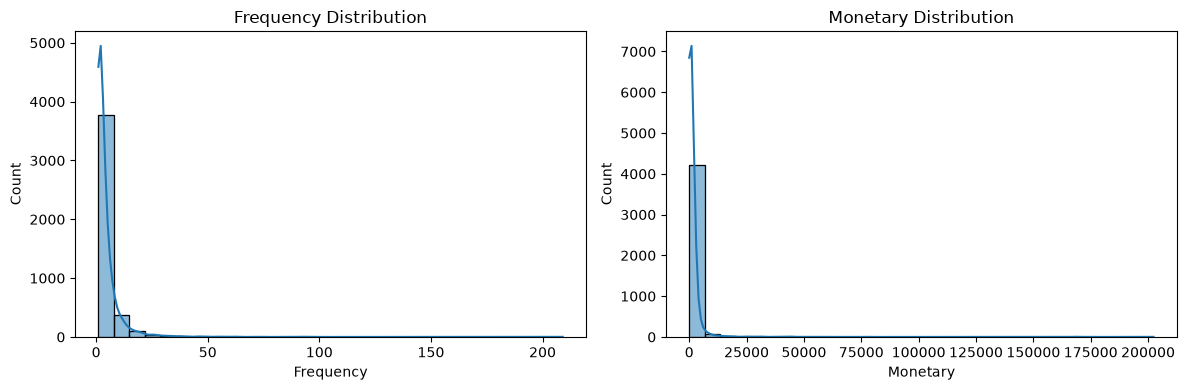

,CustomerID,Recency,Frequency,Monetary,Frequency_Log,Monetary_Log
0,12346.0,326,1,77183.60,0.693147,11.253955
1,12347.0,2,7,3125.98,2.079442,8.047823
2,12348.0,75,4,1399.80,1.609438,7.244799
3,12349.0,19,1,1209.49,0.693147,7.098781
4,12350.0,310,1,174.20,0.693147,5.165928


In [51]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(customer_df["Frequency"], bins=30, kde=True)
plt.title("Frequency Distribution")

plt.subplot(1, 2, 2)
sns.histplot(customer_df["Monetary"], bins=30, kde=True)
plt.title("Monetary Distribution")

plt.tight_layout()
plt.show()

customer_df["Frequency_Log"] = np.log1p(
    customer_df["Frequency"]
)

customer_df["Monetary_Log"] = np.log1p(
    customer_df["Monetary"]
)

customer_df.head()

**تحلیل:**

نمودارها شکل توزیع ویژگی‌ها را نشان می‌دهند. اگر بیشتر مقادیر در محدوده کوچک قرار داشته باشند و تعداد کمی مقدار بسیار بزرگ وجود داشته باشد، توزیع دارای چولگی است.

تبدیل لگاریتمی می‌تواند فاصله مقادیر بسیار بزرگ را کاهش دهد و باعث شود ویژگی‌ها برای تحلیل و خوشه‌بندی مناسب‌تر شوند.


## **سؤال 20: چگونه می‌توان ویژگی‌های عددی را استانداردسازی کرد؟**

**هدف از پرسیدن:**

قرار دادن ویژگی‌ها در مقیاس‌های قابل مقایسه؛ زیرا الگوریتم K-Means به مقیاس داده‌ها حساس است.

**پاسخ:**

برای استانداردسازی از روش Z-Score استفاده می‌کنیم.

In [52]:
model_features = [
    "Recency",
    "Frequency_Log",
    "Monetary_Log"
]

scaled_df = customer_df[model_features].copy()

for column in model_features:

    mean_value = scaled_df[column].mean()
    std_value = scaled_df[column].std()

    if std_value != 0:
        scaled_df[column] = (
            scaled_df[column] - mean_value
        ) / std_value

print("Scaled Data:")
print(scaled_df.head())

Scaled Data:
    Recency  Frequency_Log  Monetary_Log
0  2.334305      -0.955104      4.009796
1 -0.905236       1.074301      1.423561
2 -0.175339       0.386260      0.775799
3 -0.735260      -0.955104      0.658013
4  2.174328      -0.955104     -0.901127


**تحلیل:**

پس از استانداردسازی، ویژگی‌ها در مقیاس قابل مقایسه قرار می‌گیرند.

در این روش میانگین هر ویژگی تقریباً صفر و انحراف معیار آن تقریباً یک می‌شود.

این کار باعث می‌شود ویژگی‌هایی که مقادیر عددی بزرگ‌تری دارند، صرفاً به دلیل مقیاس خود تأثیر بیشتری بر الگوریتم K-Means نگذارند.

---

# بخش پنجم: ارزیابی داده‌های آماده‌شده (Data Validation)

## **سؤال 21: آیا بعد از پاک‌سازی هنوز مقدار گمشده وجود دارد؟**

**هدف از پرسیدن:**

اطمینان از اینکه داده‌های نهایی فاقد مقادیر گمشده هستند.


In [53]:
print("Missing Values:")
print(customer_df.isnull().sum())

Missing Values:
CustomerID       0
Recency          0
Frequency        0
Monetary         0
Frequency_Log    0
Monetary_Log     0
dtype: int64


**تحلیل:**

اگر مقدار همه ستون‌ها صفر باشد، یعنی در جدول نهایی مقدار گمشده وجود ندارد.

این موضوع اهمیت دارد؛ زیرا وجود مقادیر خالی می‌تواند باعث ایجاد خطا در اجرای الگوریتم‌های یادگیری ماشین شود.


## **سؤال 22: آیا دیتاست نهایی دارای رکورد تکراری است؟**

**هدف از پرسیدن:**

اطمینان از اینکه اطلاعات هر مشتری فقط یک بار در جدول نهایی ثبت شده باشد.


In [54]:
print("Duplicate Customers:")
print(customer_df["CustomerID"].duplicated().sum())

Duplicate Customers:
0


**تحلیل:**

اگر خروجی صفر باشد، یعنی شناسه تکراری در جدول مشتریان وجود ندارد.

بنابراین هر مشتری فقط یک ردیف در دیتاست نهایی خواهد داشت و اطلاعات او به‌درستی تجمیع شده است.


## **سؤال 23: آیا ویژگی‌های نهایی برای اجرای الگوریتم Clustering مناسب هستند؟**

**هدف از پرسیدن:**

بررسی نهایی ویژگی‌های انتخاب‌شده برای اطمینان از آماده بودن آن‌ها جهت خوشه‌بندی مشتریان.


In [55]:
print("Final Model Features:")
print(scaled_df.head())

print("Dataset Shape:")
print(scaled_df.shape)

print("Missing Values:")
print(scaled_df.isnull().sum())

print("Statistical Description:")
print(scaled_df.describe())

Final Model Features:
    Recency  Frequency_Log  Monetary_Log
0  2.334305      -0.955104      4.009796
1 -0.905236       1.074301      1.423561
2 -0.175339       0.386260      0.775799
3 -0.735260      -0.955104      0.658013
4  2.174328      -0.955104     -0.901127
Dataset Shape:
(4338, 3)
Missing Values:
Recency          0
Frequency_Log    0
Monetary_Log     0
dtype: int64
Statistical Description:
            Recency  Frequency_Log  Monetary_Log
count  4.338000e+03   4.338000e+03  4.338000e+03
mean   3.030208e-17  -3.931080e-17 -3.996598e-16
std    1.000000e+00   1.000000e+00  1.000000e+00
min   -9.152345e-01  -9.551042e-01 -3.811355e+00
25%   -7.452586e-01  -9.551042e-01 -7.071609e-01
50%   -4.153054e-01  -3.615411e-01 -6.017524e-02
75%    4.945657e-01   6.531617e-01  6.441232e-01
max    2.814237e+00   5.857859e+00  4.787290e+00


**تحلیل:**

در این قسمت ویژگی‌های نهایی، تعداد مشتریان، مقادیر گمشده و آمار توصیفی بررسی می‌شوند.

اگر ویژگی‌ها عددی باشند، مقدار گمشده نداشته باشند و هر مشتری یک ردیف داشته باشد، داده‌ها از نظر ساختار اولیه برای اجرای خوشه‌بندی آماده هستند.

سه ویژگی نهایی ما عبارت‌اند از:

- Recency
- Frequency_Log
- Monetary_Log

ستون CustomerID فقط برای شناسایی مشتریان نگهداری می‌شود و وارد الگوریتم Clustering نمی‌شود.


## **سؤال 24: چگونه می‌توان دیتاست آماده‌شده را ذخیره کرد؟**

**هدف از پرسیدن:**

ذخیره اطلاعات آماده‌شده برای استفاده در مراحل بعدی پروژه.

**پاسخ:**

دو فایل ذخیره می‌کنیم:

1. فایل اول شامل شناسه مشتری و ویژگی‌های RFM است.
2. فایل دوم شامل ویژگی‌های استانداردشده برای اجرای الگوریتم خوشه‌بندی است.


In [56]:
customer_df.to_csv(
    "customer_prepared.csv",
    index=False
)

scaled_df.to_csv(
    "customer_prepared_scaled.csv",
    index=False
)

print("Files Saved Successfully!")

Files Saved Successfully!


**تحلیل:**

در پایان دو فایل ذخیره می‌شوند تا در مراحل بعدی پروژه مورد استفاده قرار گیرند.

فایل اول برای بررسی مشخصات و رفتار مشتریان استفاده می‌شود و فایل دوم ورودی الگوریتم K-Means خواهد بود.

---